In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
from Moire_v2 import Moire as Moire_single
import utils

plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

In [3]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)

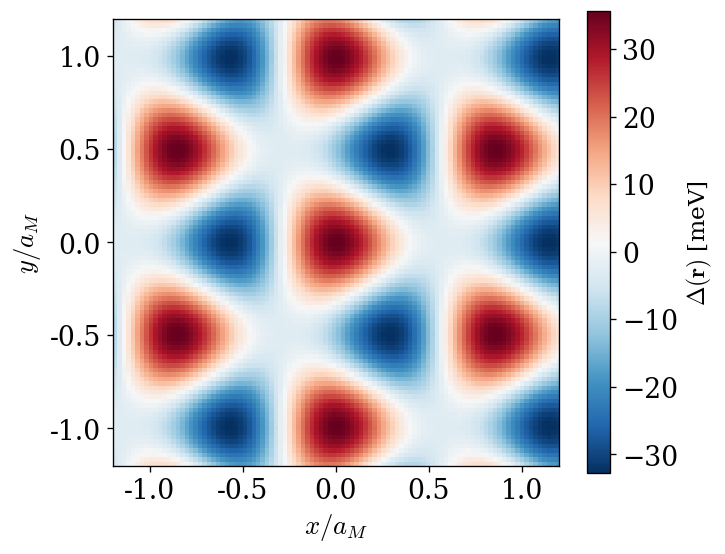

In [4]:
fig, ax = plt.subplots()
scale = 1.2
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=100)
#sys.plot_triangular_lattice(ax, extent)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta(\mathbf{r})$ [meV]", fontsize=14)

aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
#sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

### Joint Wannierization

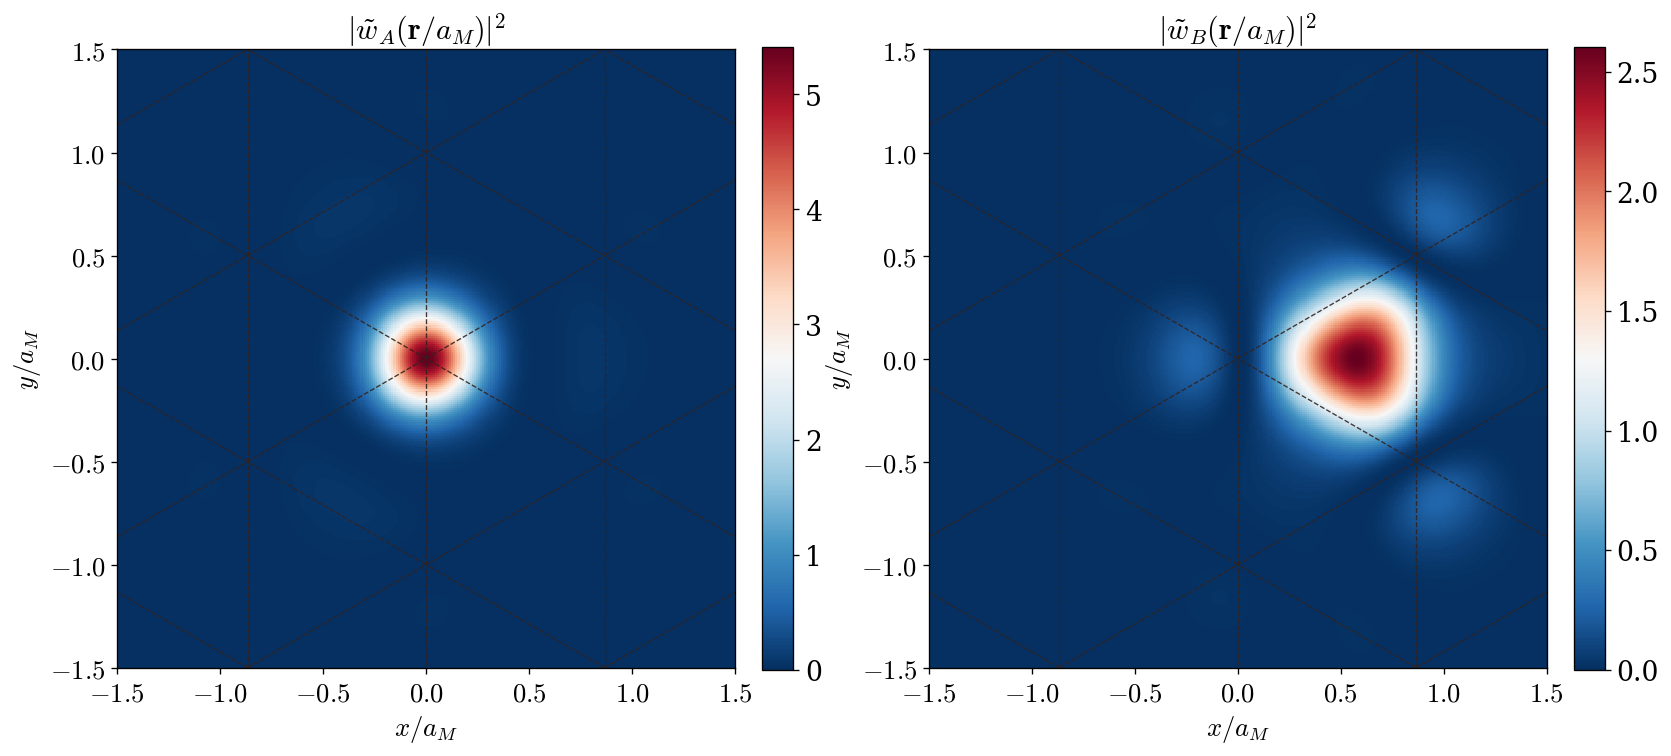

In [5]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$|\tilde{w}_A(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|\tilde{w}_B(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_joint.pdf", dpi=300, bbox_inches='tight')

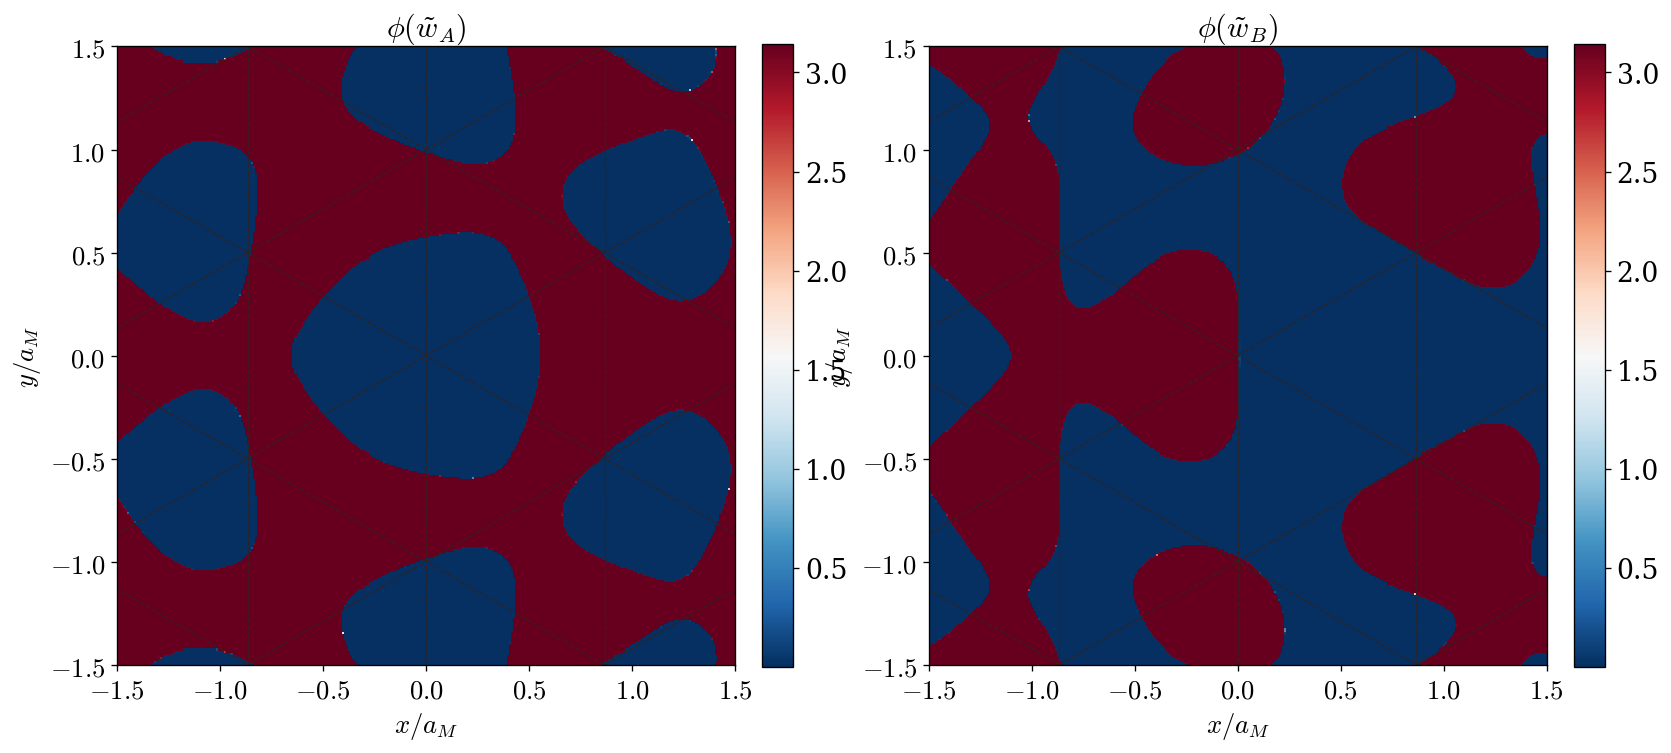

In [50]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$\phi(\tilde{w}_A)$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction_phase(ax[0], wannier1, extent, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$\phi(\tilde{w}_B)$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction_phase(ax[1], wannier2, extent, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_joint.pdf", dpi=300, bbox_inches='tight')

In [6]:
scale = 10
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]

fun_one = lambda xx, yy: 1
print("Norm1: ", sys.integrate_wannier(fun_one, wannier1, X, Y, k_points))
print("Norm2: ", sys.integrate_wannier(fun_one, wannier2, X, Y, k_points))

Norm1:  1.00000202215066
Norm2:  1.0000023703369372


### Hopping integral

In [7]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=20.0, n_shells=12)
sys_single = Moire_single(theta_deg=2.0, psi_deg=26.0, V=20.0, n_shells=12)
psis = np.linspace(0, 120, 11)
tAA = []
tAB = []
tBB = []
t1_single = []

scale = 4.0

Nx = 50
Ny = 50

for p in tqdm(psis):
    sys.psi_deg = p
    sys_single.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    tAA.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=1))
    tAB.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=1))
    tBB.append(sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=1))

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##

    if p > 60:
            Rshift = RB
    else:
        Rshift = np.zeros(2)
        
    t1_single.append(sys_single.hopping_integral(X, Y, k_points, order=1, trial_center=Rshift))

100%|██████████| 11/11 [10:30<00:00, 57.33s/it]


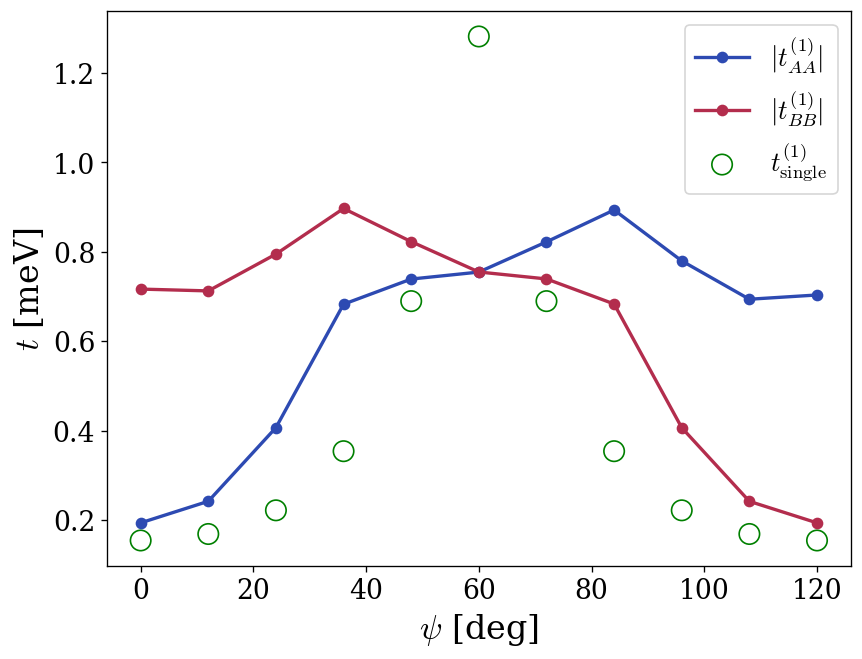

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, np.abs(tAA), marker="o", label=r"$|t_{AA}^{(1)}|$", color=cols[0])
ax.plot(psis, np.abs(tBB), marker="o", label=r"$|t_{BB}^{(1)}|$", color=cols[2])
ax.scatter(psis, t1_single, facecolors='none', edgecolors='green', s=150, marker="o",
              label=r"$t_{\text{single}}^{(1)}$", color=cols[2])
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)

# ax[1].plot(psis, tAB, marker="o", label=r"$t_{AB}^{(1)}$", color=cols[1])
# ax[1].set_xlabel(r"$\psi$ [deg]", fontsize=20)
# ax[1].legend(fontsize=16)

In [24]:
sys.theta_deg = 2.0
sys.V = 6.6
psis = np.linspace(0, 120, 21)
UAA0 = []
UBB0 = []
UAB0 = []
# UAA1 = []
# UBB1 = []
# UAB1 = []

scale = 5.0

Nx = 80
Ny = 80

for p in tqdm(psis):
    sys.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    UAA0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=0) )
    UBB0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=0) )
    UAB0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=0) )
    # UAA1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1) )
    # UBB1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=1) )
    # UAB1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="A", order=1) )

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [12:16<00:00, 35.07s/it]


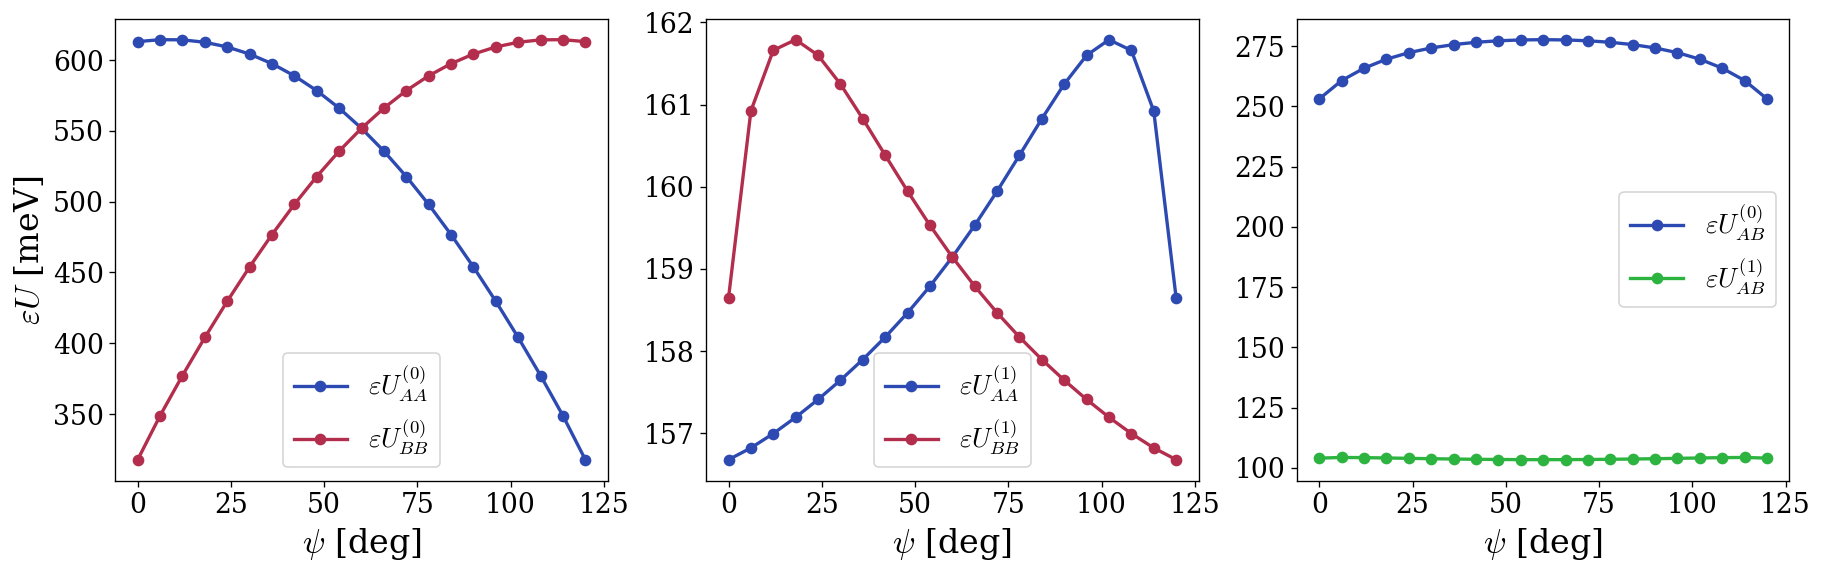

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax[0].plot(psis, UAA0, marker="o", label=r"$\varepsilon U_{AA}^{(0)}$", color=cols[0])
ax[0].plot(psis, UBB0, marker="o", label=r"$\varepsilon U_{BB}^{(0)}$", color=cols[2])
ax[0].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[0].set_ylabel(r"$\varepsilon U$ [meV]", fontsize=20)
ax[0].legend(fontsize=16)

ax[1].plot(psis, UAA1, marker="o", label=r"$\varepsilon U_{AA}^{(1)}$", color=cols[0])
ax[1].plot(psis, UBB1, marker="o", label=r"$\varepsilon U_{BB}^{(1)}$", color=cols[2])
ax[1].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[1].legend(fontsize=16)

ax[2].plot(psis, UAB0, marker="o", label=r"$\varepsilon U_{AB}^{(0)}$", color=cols[0])
ax[2].plot(psis, UAB1, marker="o", label=r"$\varepsilon U_{AB}^{(1)}$", color=cols[1])
ax[2].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[2].legend(fontsize=16)

In [35]:
sys.theta_deg = 2.0
sys.V = 6.6
psis = np.linspace(0, 120, 21)
XAA = []
XBB = []

scale = 5.0

Nx = 80
Ny = 80

for p in tqdm(psis):
    sys.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    XAA.append( sys.exchange_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1) )
    XBB.append( sys.exchange_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=1) )

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [10:30<00:00, 30.02s/it]


(1.9, 2.5)

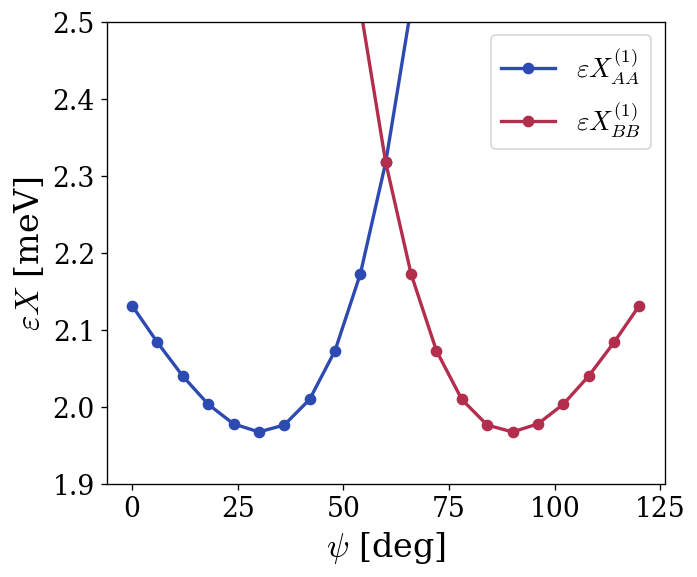

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, XAA, marker="o", label=r"$\varepsilon X_{AA}^{(1)}$", color=cols[0])
ax.plot(psis, XBB, marker="o", label=r"$\varepsilon X_{BB}^{(1)}$", color=cols[2])
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon X$ [meV]", fontsize=20)
ax.legend(fontsize=16)
ax.set_ylim([1.9, 2.5])

In [49]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)
sys_single = Moire_single(theta_deg=sys.theta_deg, psi_deg=sys.psi_deg, V=sys.V, n_shells=sys.n_shells)
thetas = np.linspace(0.5, 3.0, 10)
Xsingle = []
Xdouble = []

scale = 6.0

Nx = 100
Ny = 100

for t in tqdm(thetas):
    sys.theta_deg = t
    sys_single.theta_deg = t
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    Xdouble.append( sys.exchange_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1) )
    Xsingle.append( sys_single.exchange_interaction(X, Y, k_points, order=1, D=1e6, epsilon=1.0) )

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [05:05<00:00, 30.58s/it]


<>:9: SyntaxWarning: invalid escape sequence '\c'
<>:9: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_1050/806046560.py:9: SyntaxWarning: invalid escape sequence '\c'
  ax.set_title(r"$\psi = "+str(int(sys_single.psi_deg))+"^\circ$", fontsize=20)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


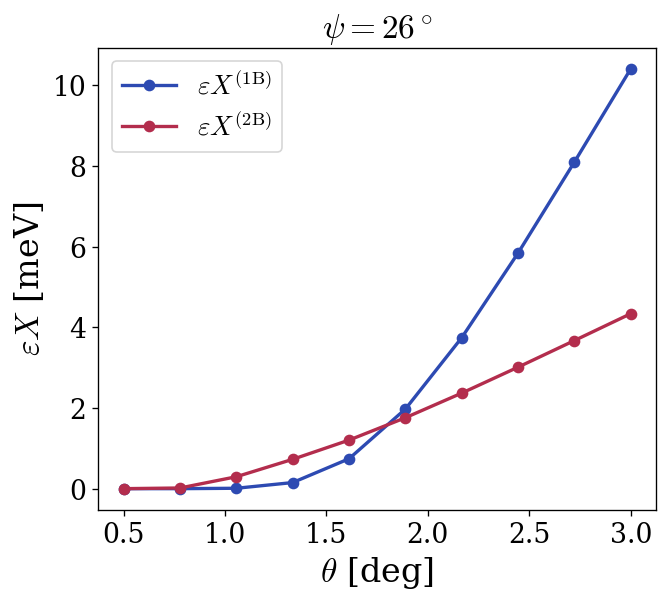

In [50]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, Xsingle, marker="o", label=r"$\varepsilon X^\text{(1B)}$", color=cols[0])
ax.plot(thetas, Xdouble, marker="o", label=r"$\varepsilon X^\text{(2B)}$", color=cols[2])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon X$ [meV]", fontsize=20)
ax.set_title(r"$\psi = "+str(int(sys_single.psi_deg))+"^\circ$", fontsize=20)
ax.legend(fontsize=16)

### Reconstructing bands

In [20]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)


scale = 5.0
Nx = 80
Ny = 80
k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

tAA0 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=np.zeros(2))
tAB0 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=np.zeros(2))
tBA0 = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="A", order=0, Rshift=np.zeros(2))
tBB0 = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=np.zeros(2))

# onsite
T0 = np.array([[tAA0, tAB0],
               [tBA0, tBB0]], dtype=complex)


hubbard_data = {
    "system": {
        "theta [deg]": sys.theta_deg,
        "psi [deg]": sys.psi_deg,
        "V [meV]": sys.V,
        "shells": sys.n_shells,
    },
    "hopping": {
        "onsite": {
            "R": [np.zeros(2)],
            "T": [T0],
        },

        "first_nn": {
            "R": [],
            "T": [],
        },

        "second_nn": {
            "R": [],
            "T": [],
        },

        "third_nn": {
            "R": [],
            "T": [],
        }
    }
}

# nearest neighbour matrices
Tnn = []

first_nn = [sys.a1, sys.a2, sys.a2 - sys.a1]
second_nn = [2 * sys.a1 - sys.a2, sys.a1 + sys.a2, 2 * sys.a2 - sys.a1]
third_nn = [2 * sys.a1, 2 * sys.a2, 2 * sys.a2 - 2 * sys.a1]

Rs = first_nn #+ second_nn #+ third_nn
neighbours = [1, 1, 1, 2, 2, 2, 3, 3, 3]
R_reduced = [sys.a1, 2 * sys.a1 - sys.a2]

for R, nn in zip(Rs, neighbours):
    tAA = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="A",
        sublattice2="A",
        order=1,
        Rshift=R
    )

    tAB = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="A",
        sublattice2="B",
        order=1,
        Rshift=R
    )

    tBA = sys.hopping_integral(
            X, Y, k_points,
            sublattice1="B",
            sublattice2="A",
            order=1,
            Rshift=R
        )

    tBB = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="B",
        sublattice2="B",
        order=1,
        Rshift=R
    )

    T = np.array([[tAA, tAB],
                  [tBA, tBB]], dtype=complex)

    hubbard_data["hopping"][f"first_nn" if nn == 1 else f"second_nn" if nn == 2 else f"third_nn"]["R"].append(R)
    hubbard_data["hopping"][f"first_nn" if nn == 1 else f"second_nn" if nn == 2 else f"third_nn"]["T"].append(T)
    Tnn.append(T)

def Hk_all(k_points, T0, Rs, Tnn):
    H = np.broadcast_to(T0, (len(k_points), 2, 2)).copy()

    for R, T in zip(Rs, Tnn):
        phase = np.exp(1j * k_points @ R)

        H += phase[:, None, None] * T
        H += phase.conj()[:, None, None] * T.conj().T

    return H

In [15]:
hubbard_data["coulomb_interactions"] = {
        "onsite": {},

        "first_nn": {},

        "second_nn": {},}

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

R0 = np.zeros(2)
R1 = sys.a1
R2 = 2 * sys.a1 - sys.a2

UAA0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=R0)
UBB0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=R0)
UAB0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=R0)
UAA1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1, Rshift=R1)
UBB1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=1, Rshift=R1)
UAB1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=1, Rshift=R1)

hubbard_data["coulomb_interactions"]["onsite"]["UAA"] = UAA0
hubbard_data["coulomb_interactions"]["onsite"]["UBB"] = UBB0
hubbard_data["coulomb_interactions"]["onsite"]["UAB"] = UAB0
hubbard_data["coulomb_interactions"]["first_nn"]["UAA"] = UAA1
hubbard_data["coulomb_interactions"]["first_nn"]["UBB"] = UBB1
hubbard_data["coulomb_interactions"]["first_nn"]["UAB"] = UAB1

KeyboardInterrupt: 

In [ ]:
import yaml
import numpy as np

def convert_for_yaml(obj):
    if isinstance(obj, np.ndarray):
        return convert_for_yaml(obj.tolist())

    if isinstance(obj, dict):
        return {
            k: convert_for_yaml(v)
            for k, v in obj.items()
        }

    if isinstance(obj, (list, tuple)):
        return [convert_for_yaml(v) for v in obj]

    if isinstance(obj, complex):
        return f"{obj.real:.3f}{obj.imag:+.3f}j"

    if isinstance(obj, np.generic):
        return obj.item()

    return obj



with open("data/honeycomb_hubbard_theta"+str(sys.theta_deg)+"_psi"+str(sys.psi_deg)+"_V"+str(sys.V)+".yaml", "w") as f:
    yaml.safe_dump(
        convert_for_yaml(hubbard_data),
        f,
        sort_keys=False,
        default_flow_style=None
    )

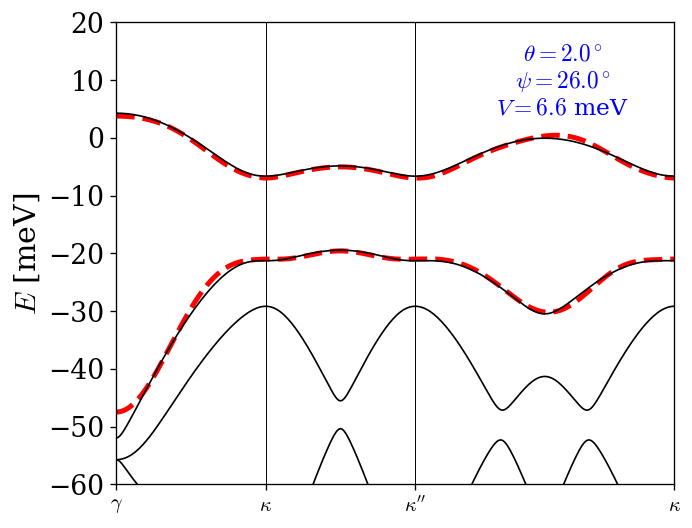

In [19]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
H = Hk_all(kpath, T0, Rs, Tnn)
energies, vectors = np.linalg.eigh(H)
energies = energies[:, ::-1]

fig, ax = plt.subplots()
sys.plot_bands(ax, energies, kdist, ticks, max_bands=2, linestyle="--", lw=3, color="red")

## ED Bands
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4, lw=1)

plt.ylim([-60, 20])
plt.text(0.8, 0.8, rf"$\theta = {sys.theta_deg:.1f}^\circ$" "\n"
    rf"$\psi = {sys.psi_deg:.1f}^\circ$" "\n"
    rf"$V = {sys.V:.1f}$ meV", 
    transform=ax.transAxes, fontsize=14, ha="center", color="blue")
plt.savefig("data/honeycomb_fit_theta"+str(sys.theta_deg)+"_psi"+str(sys.psi_deg)+"_V"+str(sys.V)+".pdf", dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)

### Procedure 2 (Notation)

We will reduce the calculation to a small amount of hoppings. In this case we will keep first nearest neighbours (A to B) and second nearest (A to A).

- Onsite energies: $\epsilon_A$ and $\epsilon_B$
- 1st nn: $t_{AB}$
- 2nd nn: $t_{AA}$

In [5]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)


scale = 5.0
Nx = 80
Ny = 80
k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

In [6]:
shift = np.zeros(2)
onsiteA = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=shift)
onsiteB = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=shift)

tAB = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=shift)

shift = sys.a1
tAA = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=shift)
tBB = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=shift)

shift = sys.a2
tAB2 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=shift)

shift = sys.a1 + sys.a2
tAA2 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=shift)
tBB2 = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=shift)

In [7]:
print("onsiteA: ", onsiteA)
print("onsiteB: ", onsiteB, "\n")
print("First nn")
print("tAB: ", tAB, "\n")
print("Second nn")
print("tAA: ", tAA)
print("tBB: ", tBB)
print("Third nn")
print("tAB2: ", tAB2)

onsiteA:  (-8.606865129728451+3.8214466746059015e-07j)
onsiteB:  (-20.787645811027197-4.7005539401447874e-07j) 

First nn
tAB:  (6.972685365982031-2.9669615167012405e-07j) 

Second nn
tAA:  (-1.1797896842734938-3.7866665148076925e-06j)
tBB:  (-0.5696660556702106-1.0055426587021983e-06j)
Third nn
tAB2:  (1.389227087872424+9.93952460161531e-07j)


In [64]:
deltaB = (2 * sys.a1 - sys.a2) / 3

phi = np.radians(120)
rot120 = np.array([[np.cos(phi), -np.sin(phi)],
                    [np.sin(phi), np.cos(phi)]])

R_first_nn = [deltaB, rot120 @ deltaB, (rot120 @ rot120) @ deltaB]
R_second_nn = [sys.a1, sys.a2, sys.a2 - sys.a1]

delta3 = deltaB + sys.a2
R_third_nn = [delta3, rot120 @ delta3, (rot120 @ rot120) @ delta3]

def H_TB_honeycomb(k_points, onsiteA, onsiteB, tAB, tAA, tBB, tAB2):
    T0 = np.array([
        [onsiteA, 0.0],
        [0.0, onsiteB]
    ], dtype=complex)

    H = np.broadcast_to(
        T0, (len(k_points), 2, 2)
    ).copy()

    # ------------------------------------------------------------
    # Nearest-neighbour A-B hopping
    # ------------------------------------------------------------

    H_AB = np.zeros(len(k_points), dtype=complex)

    for R, R3 in zip(R_first_nn, R_third_nn):
        phase = np.exp(
            1j * np.einsum("ki,i->k", k_points, R)
        )

        phase3 = np.exp(
            1j * np.einsum("ki,i->k", k_points, R3)
        )

        H_AB += tAB * phase
        H_AB += tAB2 * phase3

    H[:, 0, 1] = H_AB
    H[:, 1, 0] = np.conj(H_AB)

    # ------------------------------------------------------------
    # Second-neighbour A-A and B-B hopping
    # ------------------------------------------------------------

    for R in R_second_nn:

        phase = np.exp(
            1j * np.einsum("ki,i->k", k_points, R)
        )

        # tAA is assumed real
        H[:, 0, 0] += tAA * (phase + np.conj(phase))
        H[:, 1, 1] += tBB * (phase + np.conj(phase))

    return H

Text(0.8, 0.65, '$\\theta = 2.0^\\circ$\n$\\psi = 26.0^\\circ$\n$V = 6.6$ meV')

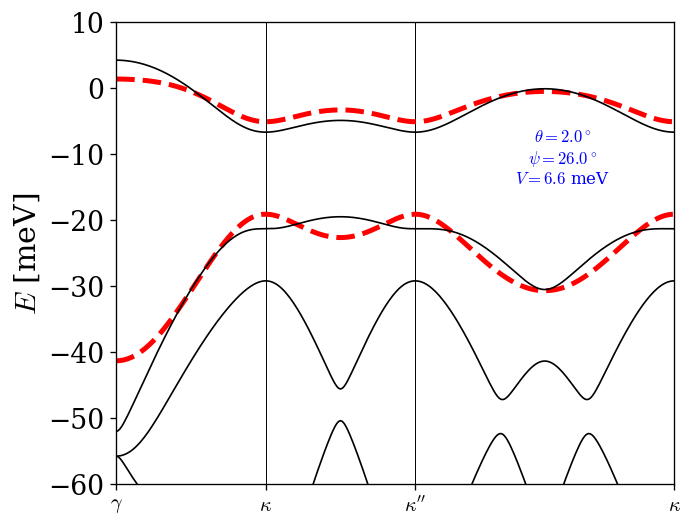

In [67]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
H = H_TB_honeycomb(kpath, onsiteA, onsiteB, tAB, tAA, tBB, 0)
energies, vectors = np.linalg.eigh(H)
energies = energies[:, ::-1]

fig, ax = plt.subplots()
sys.plot_bands(ax, energies, kdist, ticks, max_bands=2, linestyle="--", lw=3, color="red")

## ED Bands
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4, lw=1)

plt.ylim([-60, 10])
plt.text(0.8, 0.65, rf"$\theta = {sys.theta_deg:.1f}^\circ$" "\n"
    rf"$\psi = {sys.psi_deg:.1f}^\circ$" "\n"
    rf"$V = {sys.V:.1f}$ meV", 
    transform=ax.transAxes, fontsize=10, ha="center", color="blue")

In [56]:
scale = 8.0
Nx = 100
Ny = 100
sys.theta_deg = 2.0
psis = np.linspace(0, 120, 11)
tAB = []
tAB_kspace = []
tAA = []
tAA_kspace = []
tBB = []
tBB_kspace = []

for p in tqdm(psis):
    sys.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##
    
    # if p > 60:
    #     Rshift = RB
    # else:
    #     Rshift = np.zeros(2)

    shift = np.zeros(2)
    tAB.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=shift))

    R = np.zeros(2)   # or whichever A -> B displacement you want

    trial_centers = np.array([RA, RB])
    t_R = sys.hopping_from_wannier_gauge(
        k_points=k_points,
        trial_centers=trial_centers,
        R=R,
        band_indices=(-2, -1),
    )

    tAB_kspace.append(t_R[0, 1])
    shift = sys.a1
    tAA.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=shift))
    tBB.append(sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=shift))

    R = sys.a1   # or whichever A -> B displacement you want
    
    trial_centers = np.array([RA, RB])
    t_R = sys.hopping_from_wannier_gauge(
        k_points=k_points,
        trial_centers=trial_centers,
        R=R,
        band_indices=(-2, -1),
    )
    tAA_kspace.append(t_R[0, 0])
    tBB_kspace.append(t_R[1, 1])

  0%|          | 0/11 [00:00<?, ?it/s]

100%|██████████| 11/11 [15:47<00:00, 86.11s/it]


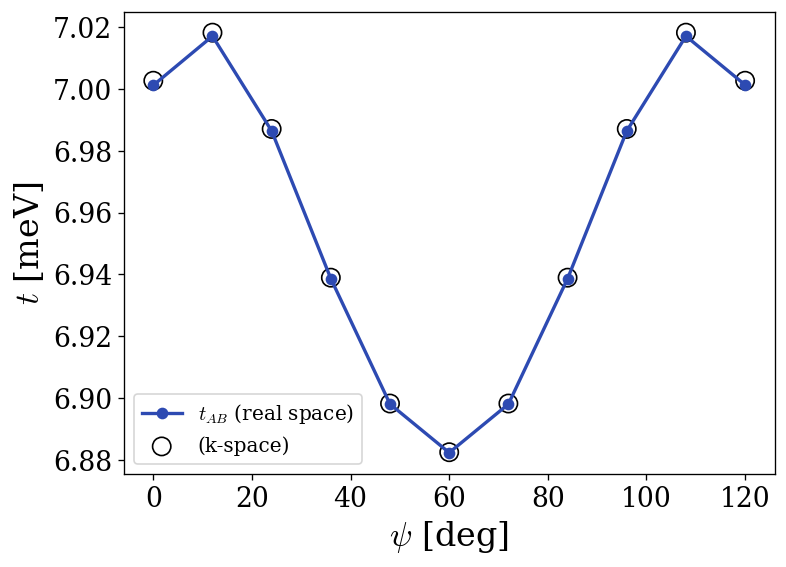

In [57]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, tAB, marker="o", label=r"$t_{AB}$ (real space)", color=cols[0])
ax.scatter(psis, tAB_kspace, marker="o", label=r"(k-space)", color="k", s=120, facecolor="none", linewidth=1)
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=12)

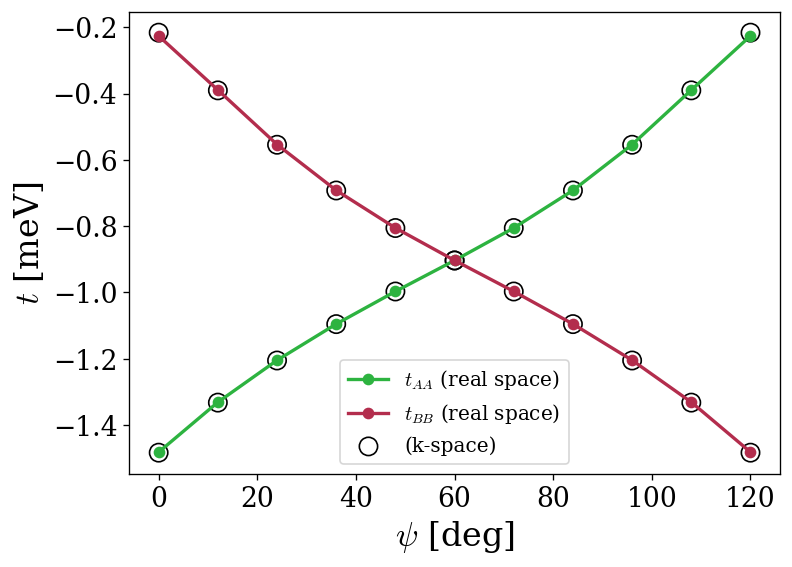

In [58]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, tAA, marker="o", label=r"$t_{AA}$ (real space)", color=cols[1])
ax.plot(psis, tBB, marker="o", label=r"$t_{BB}$ (real space)", color=cols[2])
ax.scatter(psis, tAA_kspace, marker="o", label=None, color="k", s=120, facecolor="none", linewidth=1)
ax.scatter(psis, tBB_kspace, marker="o", label=r"(k-space)", color="k", s=120, facecolor="none", linewidth=1)
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=12)

### Function of twist-angle

In [110]:
sys = Moire(theta_deg=2.0, psi_deg=20.0, V=8, n_shells=10, epsilon_sim=15.0)

In [ ]:
scale = 8.0
Nx = 100
Ny = 100
thetas = np.linspace(0.6, 3.0, 11)
tAB = []
tAB_kspace = []
tAA = []
tAA_kspace = []
tBB = []
tBB_kspace = []

for t in tqdm(thetas):
    sys.theta_deg = t
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##
    
    # if p > 60:
    #     Rshift = RB
    # else:
    #     Rshift = np.zeros(2)

    shift = np.zeros(2)
    # tAB.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=shift))

    R = np.zeros(2)   # or whichever A -> B displacement you want

    trial_centers = np.array([RA, RB])
    t_R = sys.hopping_from_wannier_gauge(
        k_points=k_points,
        trial_centers=trial_centers,
        R=R,
        band_indices=(-2, -1),
    )

    tAB_kspace.append(t_R[0, 1])
    shift = sys.a1
    # tAA.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=shift))
    # tBB.append(sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=shift))

    R = sys.a1   # or whichever A -> B displacement you want
    
    trial_centers = np.array([RA, RB])
    t_R = sys.hopping_from_wannier_gauge(
        k_points=k_points,
        trial_centers=trial_centers,
        R=R,
        band_indices=(-2, -1),
    )
    tAA_kspace.append(t_R[0, 0])
    tBB_kspace.append(t_R[1, 1])

  0%|          | 0/11 [00:00<?, ?it/s]

  9%|▉         | 1/11 [00:01<00:15,  1.58s/it]

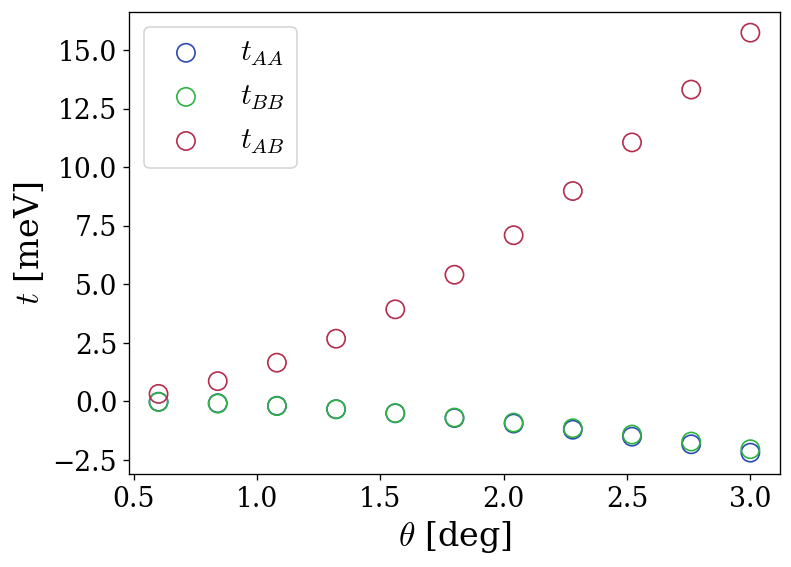

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

# ax.plot(thetas, tAA, color=cols[0])
# ax.plot(thetas, tBB, color=cols[1])
# ax.plot(thetas, tAB, color=cols[2])
ax.scatter(thetas, tAA_kspace, marker="o", label="$t_{AA}$", color=cols[0], s=120, facecolor="none", linewidth=1)
ax.scatter(thetas, tBB_kspace, marker="o", label=r"$t_{BB}$", color=cols[1], s=120, facecolor="none", linewidth=1)
ax.scatter(thetas, tAB_kspace, marker="o", label=r"$t_{AB}$", color=cols[2], s=120, facecolor="none", linewidth=1)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=18)

In [ ]:
scale = 5.0

Nx = 80
Ny = 80

UA = []
UB = []
Delta = []

for t in tqdm(thetas):
    sys.theta_deg = t
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    UA.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, epsilon=sys.epsilon_sim) )
    UB.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, epsilon=sys.epsilon_sim) )

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##
    
    # if p > 60:
    #     Rshift = RB
    # else:
    #     Rshift = np.zeros(2)

    shift = np.zeros(2)
    # tAB.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=shift))

    R = np.zeros(2)   # or whichever A -> B displacement you want

    trial_centers = np.array([RA, RB])
    T0 = sys.hopping_from_wannier_gauge(
        k_points=k_points,
        trial_centers=trial_centers,
        R=R,
        band_indices=(-2, -1),
    )
    Delta.append(T0[0, 0] - T0[1, 1])

100%|██████████| 11/11 [03:59<00:00, 21.82s/it]


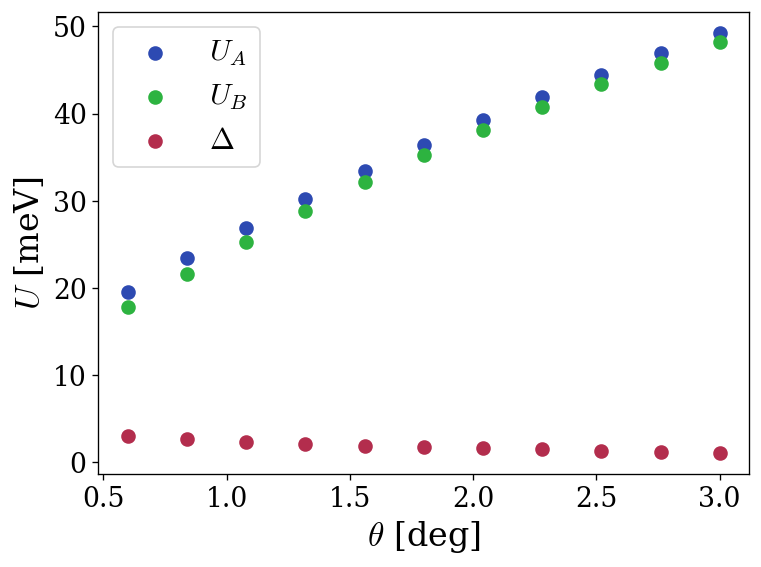

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.scatter(thetas, UA, marker="o", label="$U_A$", color=cols[0], s=60, facecolor=cols[0], linewidth=1)
ax.scatter(thetas, UB, marker="o", label=r"$U_B$", color=cols[1], s=60, facecolor=cols[1], linewidth=1)
ax.scatter(thetas, Delta, marker="o", label=r"$\Delta$", color=cols[2], s=60, facecolor=cols[2], linewidth=1)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$U$ [meV]", fontsize=20)
ax.legend(fontsize=18)

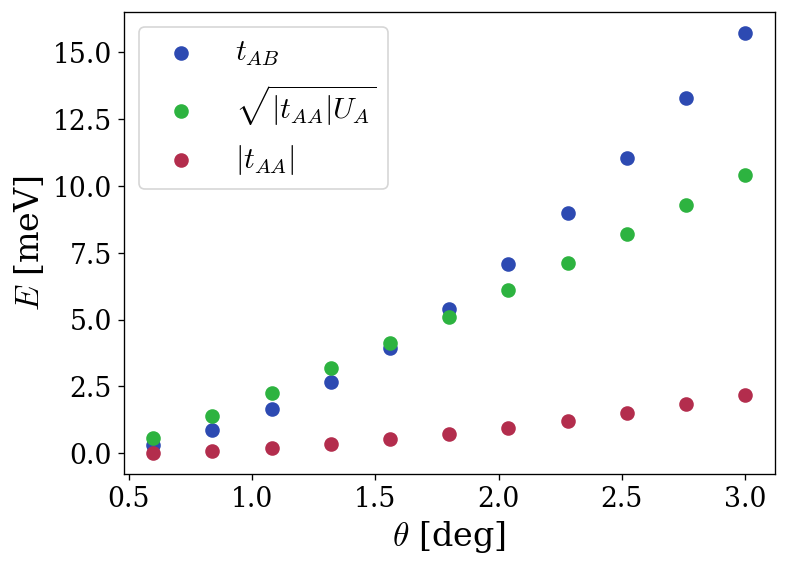

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.scatter(thetas, tAB_kspace, marker="o", label=r"$t_{AB}$", color=cols[0], s=60, facecolor=cols[0], linewidth=1)
ax.scatter(thetas, np.sqrt(np.abs(tAA_kspace) * np.array(UA)), marker="o", label=r"$\sqrt{|t_{AA}|U_A}$", color=cols[1], s=60, facecolor=cols[1], linewidth=1)
ax.scatter(thetas, np.abs(tAA_kspace), marker="o", label=r"$|t_{AA}|$", color=cols[2], s=60, facecolor=cols[2], linewidth=1)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$E$ [meV]", fontsize=20)
ax.legend(fontsize=18)

### Single band

In [11]:
sys = Moire_single(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)

scale = 5.0
Nx = 80
Ny = 80
k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

t0 = sys.hopping_integral(X, Y, k_points, order=0, Rshift=np.zeros(2))

# onsite
T0 = t0

# nearest neighbour matrices
Tnn = []

first_nn = [sys.a1, sys.a2, sys.a2 - sys.a1]
second_nn = [2 * sys.a1 - sys.a2, sys.a1 + sys.a2, 2 * sys.a2 - sys.a1]
third_nn = [2 * sys.a1, 2 * sys.a2, 2 * sys.a2 - 2 * sys.a1]

Rs = first_nn + second_nn + third_nn

for R in Rs:
    t = sys.hopping_integral(
        X, Y, k_points,
        order=1,
        Rshift=R
    )

    T = t

    Tnn.append(T)

def Hk_all(k_points, T0, Rs, Tnn):
    H = np.full(len(k_points), T0, dtype=complex)

    for R, t in zip(Rs, Tnn):
        phase = np.exp(1j * (k_points @ R))
        H += phase * t
        H += phase.conj() * np.conj(t)

    return H

/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(-60.0, 10.0)

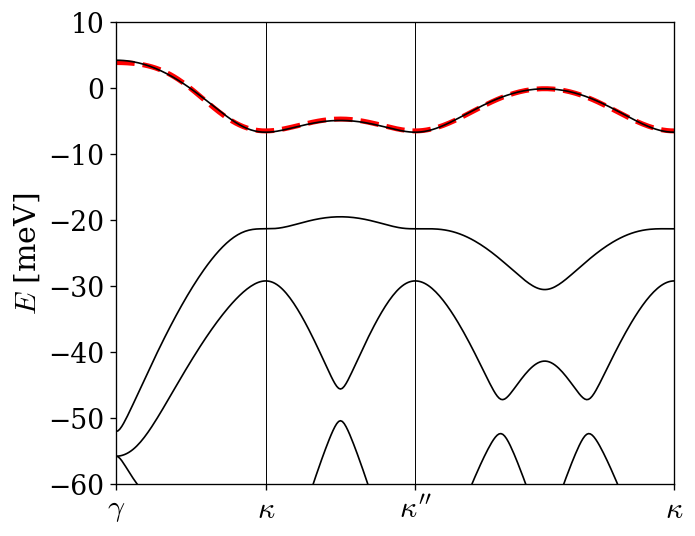

In [13]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
H = Hk_all(kpath, T0, Rs, Tnn)
# energies, vectors = np.linalg.eigh(H)
# energies = energies[:, ::-1]

fig, ax = plt.subplots()
sys.plot_bands(ax, H, kdist, ticks, max_bands=2, linestyle="--", lw=3, color="red")

## ED Bands
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4, lw=1)

plt.ylim([-60, 10])
# plt.text(0.8, 0.8, rf"$\theta = {sys.theta_deg:.1f}^\circ$" "\n"
#     rf"$\psi = {sys.psi_deg:.1f}^\circ$" "\n"
#     rf"$V = {sys.V:.1f}$ meV", 
#     transform=ax.transAxes, fontsize=14, ha="center", color="blue")
#plt.savefig("plots/two_bands.svg", dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)

In [139]:
print(T0)

(-1.9402809584873193-1.4881093309092723e-07j)


In [140]:
print(Tnn)

[(1.2463620488196567+1.0497575054120182e-06j), (1.24637785871652+5.166068832574336e-07j), (1.2463589896461338-1.2634860141192482e-08j), (-0.17658188761306315-6.053501579310226e-07j), (-0.17661591186517844+3.01436364516422e-07j), (-0.17664649024103957+2.7420446558847186e-07j), (-0.09527795157332578-7.420490716832073e-07j), (-0.0952464115945501-3.9944148601501586e-07j), (-0.0952553660525022+3.8343040181103176e-08j)]
